# Homework 2: GAN on the assigned WikiArt dataset

This notebook trains a 64x64 painting GAN on a **seeded 2,390-image subset downloaded directly from the attached [steubk/wikiart](https://www.kaggle.com/datasets/steubk/wikiart) Kaggle dataset**. It records provenance, losses, generated images, Inception Score, and FID. The model and metrics are saved under `/kaggle/working/homework2-wikiart-gan/`.

Before running: attach `steubk/wikiart` through **Add Input**, select a **GPU** accelerator, and enable **Internet** for the small Ignite package and pretrained Inception weights. Then choose **Save Version > Save & Run All** to persist the outputs.


In [1]:
from pathlib import Path
PROJECT = Path('/kaggle/working/homework2-wikiart-gan')
PROJECT.mkdir(parents=True, exist_ok=True)
print('Project:', PROJECT)
print('Attached inputs:', [p.name for p in Path('/kaggle/input').iterdir()])


Project: /kaggle/working/homework2-wikiart-gan
Attached inputs: ['datasets']


In [2]:
%%writefile /kaggle/working/homework2-wikiart-gan/gan.py
"""64 x 64 deep convolutional GAN for RGB paintings."""

import torch
from torch import nn
from torch.nn.utils import spectral_norm


class Generator(nn.Module):
    def __init__(self, latent_dim=100, width=64):
        super().__init__()
        self.latent_dim = latent_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, width * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(width * 8), nn.ReLU(True),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(width * 8, width * 4, 3, 1, 1, bias=False),
            nn.BatchNorm2d(width * 4), nn.ReLU(True),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(width * 4, width * 2, 3, 1, 1, bias=False),
            nn.BatchNorm2d(width * 2), nn.ReLU(True),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(width * 2, width, 3, 1, 1, bias=False),
            nn.BatchNorm2d(width), nn.ReLU(True),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv2d(width, 3, 3, 1, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.net(noise)


class Discriminator(nn.Module):
    def __init__(self, width=64):
        super().__init__()
        self.net = nn.Sequential(
            spectral_norm(nn.Conv2d(3, width, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            spectral_norm(nn.Conv2d(width, width * 2, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            spectral_norm(nn.Conv2d(width * 2, width * 4, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            spectral_norm(nn.Conv2d(width * 4, width * 8, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            spectral_norm(nn.Conv2d(width * 8, 1, 4, 1, 0)),
        )

    def forward(self, images):
        return self.net(images).reshape(-1)


def init_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(getattr(module, "weight_orig", module.weight), 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


def noise_batch(count, latent_dim, device):
    return torch.randn(count, latent_dim, 1, 1, device=device)


Writing /kaggle/working/homework2-wikiart-gan/gan.py


In [3]:
%%writefile /kaggle/working/homework2-wikiart-gan/train.py
"""Train the WikiArt DCGAN and save losses, checkpoints, and image grids."""

import argparse
import csv
import json
import random
import time
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import save_image

from gan import Discriminator, Generator, init_weights, noise_batch


def make_dataset(root, seed, holdout_fraction=0.2):
    transform = transforms.Compose([
        transforms.Resize(72), transforms.CenterCrop(64),
        transforms.ToTensor(), transforms.Normalize((0.5,) * 3, (0.5,) * 3),
    ])
    dataset = datasets.ImageFolder(root, transform=transform)
    if len(dataset) < 100:
        raise ValueError("At least 100 downloaded images are required")
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(dataset))
    count = int(len(dataset) * holdout_fraction)
    return dataset, Subset(dataset, order[count:].tolist()), Subset(dataset, order[:count].tolist())


def save_grid(generator, fixed_noise, path):
    generator.eval()
    with torch.inference_mode():
        images = generator(fixed_noise).cpu()
    save_image(images, path, nrow=8, normalize=True, value_range=(-1, 1))
    generator.train()


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--data", type=Path, required=True)
    p.add_argument("--output", type=Path, required=True)
    p.add_argument("--epochs", type=int, default=15)
    p.add_argument("--batch-size", type=int, default=64)
    p.add_argument("--latent-dim", type=int, default=100)
    p.add_argument("--width", type=int, default=64)
    p.add_argument("--lr-g", type=float, default=0.0002)
    p.add_argument("--lr-d", type=float, default=0.0001)
    p.add_argument("--seed", type=int, default=2026)
    p.add_argument("--workers", type=int, default=4)
    p.add_argument("--max-steps", type=int, default=0, help="For a quick smoke test only")
    args = p.parse_args()
    args.output.mkdir(parents=True, exist_ok=True)
    random.seed(args.seed)
    np.random.seed(args.seed)
    torch.manual_seed(args.seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(args.seed)
        torch.backends.cudnn.benchmark = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    full, train, holdout = make_dataset(args.data, args.seed)
    loader = DataLoader(train, batch_size=args.batch_size, shuffle=True,
                        num_workers=args.workers, pin_memory=device.type == "cuda",
                        drop_last=True, persistent_workers=args.workers > 0)
    generator = Generator(args.latent_dim, args.width).to(device).apply(init_weights)
    discriminator = Discriminator(args.width).to(device).apply(init_weights)
    optim_g = torch.optim.Adam(generator.parameters(), lr=args.lr_g, betas=(0.0, 0.9))
    optim_d = torch.optim.Adam(discriminator.parameters(), lr=args.lr_d, betas=(0.0, 0.9))
    fixed_noise = noise_batch(64, args.latent_dim, device)
    sample_real = torch.stack([train[i][0] for i in range(64)])
    save_image(sample_real, args.output / "real_grid.png", nrow=8,
               normalize=True, value_range=(-1, 1))
    config = vars(args).copy()
    config.update(device=str(device), dataset_size=len(full), train_size=len(train),
                  holdout_size=len(holdout), classes=full.classes,
                  torch_version=torch.__version__)
    config = {key: str(value) if isinstance(value, Path) else value for key, value in config.items()}
    (args.output / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    start = time.time()
    with (args.output / "losses.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["epoch", "step", "loss_d", "loss_g"])
        step = 0
        for epoch in range(1, args.epochs + 1):
            d_total = g_total = batches = 0
            for real, _ in loader:
                real = real.to(device, non_blocking=True)
                count = real.size(0)
                # Spectral-normalized discriminator with the hinge objective.
                optim_d.zero_grad(set_to_none=True)
                real_logits = discriminator(real)
                fake = generator(noise_batch(count, args.latent_dim, device))
                fake_logits = discriminator(fake.detach())
                loss_d = torch.relu(1 - real_logits).mean() + torch.relu(1 + fake_logits).mean()
                loss_d.backward()
                optim_d.step()
                # Generator maximizes discriminator scores for synthetic images.
                optim_g.zero_grad(set_to_none=True)
                fake_logits = discriminator(fake)
                loss_g = -fake_logits.mean()
                loss_g.backward()
                optim_g.step()
                step += 1
                batches += 1
                d_total += loss_d.item()
                g_total += loss_g.item()
                writer.writerow([epoch, step, loss_d.item(), loss_g.item()])
                if step % 20 == 0:
                    print(f"epoch {epoch}/{args.epochs} step {step}: D={loss_d.item():.3f} G={loss_g.item():.3f}", flush=True)
                if args.max_steps and step >= args.max_steps:
                    break
            stream.flush()
            save_grid(generator, fixed_noise, args.output / f"samples_epoch_{epoch:02d}.png")
            checkpoint = {"generator": generator.state_dict(), "discriminator": discriminator.state_dict(),
                          "optim_g": optim_g.state_dict(), "optim_d": optim_d.state_dict(),
                          "epoch": epoch, "step": step, "config": config}
            torch.save(checkpoint, args.output / "checkpoint.pt")
            print(f"epoch {epoch} complete: D={d_total/batches:.3f} G={g_total/batches:.3f}; "
                  f"elapsed={(time.time()-start)/60:.1f} min", flush=True)
            if args.max_steps and step >= args.max_steps:
                break


if __name__ == "__main__":
    main()


Writing /kaggle/working/homework2-wikiart-gan/train.py


In [4]:
%%writefile /kaggle/working/homework2-wikiart-gan/evaluate.py
"""Compute Ignite Inception Score and FID against held-out WikiArt images."""

import argparse
import json
from pathlib import Path

import torch
from ignite.metrics import FID, InceptionScore
from ignite.metrics.gan.utils import InceptionModel
from torch.utils.data import DataLoader
from torchvision.transforms.functional import resize

from gan import Generator, noise_batch
from train import make_dataset


def inception_input(images):
    # Both the real and generated images originate in [-1, 1].
    images = ((images + 1) / 2).clamp(0, 1)
    return resize(images, [299, 299], antialias=True)


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--checkpoint", type=Path, required=True)
    p.add_argument("--data", type=Path, required=True)
    p.add_argument("--output", type=Path, required=True)
    p.add_argument("--batch-size", type=int, default=16)
    p.add_argument("--max-images", type=int, default=300)
    args = p.parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    state = torch.load(args.checkpoint, map_location=device, weights_only=False)
    config = state["config"]
    generator = Generator(config["latent_dim"], config["width"]).to(device)
    generator.load_state_dict(state["generator"])
    generator.eval()
    _, _, holdout = make_dataset(args.data, config["seed"])
    count = min(args.max_images, len(holdout))
    loader = DataLoader(torch.utils.data.Subset(holdout, range(count)),
                        batch_size=args.batch_size, shuffle=False, num_workers=0)
    # Ignite's blog defaults to 1000-dimensional class probabilities for FID.
    # Pool3 features are the conventional, more interpretable FID variant.
    fid = FID(num_features=2048,
              feature_extractor=InceptionModel(return_features=True, device=device),
              device=device)
    fid_blog = FID(device=device)
    inception_score = InceptionScore(device=device)
    fid.reset()
    fid_blog.reset()
    inception_score.reset()
    torch.manual_seed(config["seed"] + 1)
    with torch.inference_mode():
        for i, (real, _) in enumerate(loader, 1):
            real = real.to(device)
            fake = generator(noise_batch(real.size(0), config["latent_dim"], device))
            real = inception_input(real)
            fake = inception_input(fake)
            fid.update((fake, real))
            fid_blog.update((fake, real))
            inception_score.update(fake)
            print(f"Evaluated {min(i * args.batch_size, count)}/{count} image pairs", flush=True)
    result = {"fid_pool3": float(fid.compute()),
              "fid_ignite_blog_default": float(fid_blog.compute()),
              "inception_score": float(inception_score.compute()),
              "real_images": count, "generated_images": count,
              "checkpoint_epoch": state["epoch"], "metric_library": "pytorch-ignite",
              "resize": "bilinear antialias to 299x299", "real_split": "held-out 20%"}
    args.output.parent.mkdir(parents=True, exist_ok=True)
    args.output.write_text(json.dumps(result, indent=2), encoding="utf-8")
    print(json.dumps(result, indent=2))


if __name__ == "__main__":
    main()


Writing /kaggle/working/homework2-wikiart-gan/evaluate.py


In [5]:
%%writefile /kaggle/working/homework2-wikiart-gan/plot_losses.py
"""Plot raw and smoothed losses saved by train.py."""

import argparse
import csv
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


def smooth(values, window=25):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return values
    kernel = np.ones(window)
    return np.convolve(values, kernel, mode="same") / np.convolve(np.ones_like(values), kernel, mode="same")


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--losses", type=Path, required=True)
    p.add_argument("--output", type=Path, required=True)
    args = p.parse_args()
    with args.losses.open(newline="", encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    steps = [int(row["step"]) for row in rows]
    fig, ax = plt.subplots(figsize=(8, 3.5), dpi=180)
    for key, color, label in (("loss_d", "#1e6091", "Discriminator"),
                              ("loss_g", "#c45d39", "Generator")):
        values = np.array([float(row[key]) for row in rows])
        ax.plot(steps, values, color=color, alpha=0.18, linewidth=0.7)
        ax.plot(steps, smooth(values), color=color, linewidth=1.7, label=label)
    ax.set(xlabel="Training step", ylabel="Hinge objective")
    ax.grid(alpha=0.16)
    ax.legend(frameon=False)
    fig.tight_layout()
    args.output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(args.output)


if __name__ == "__main__":
    main()


Writing /kaggle/working/homework2-wikiart-gan/plot_losses.py


In [6]:
%%writefile /kaggle/working/homework2-wikiart-gan/prepare_kaggle_subset.py
"""Prepare a seeded image subset from the assigned Kaggle WikiArt upload."""

import argparse
import json
import random
from pathlib import Path

from PIL import Image, ImageOps


EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}


def locate_source(input_root):
    matches = list(input_root.glob("*/Abstract_Expressionism"))
    if not matches:
        matches = list(input_root.glob("*/*/Abstract_Expressionism"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one mounted WikiArt dataset with an Abstract_Expressionism folder under {input_root}; "
            f"found {len(matches)}. Attach steubk/wikiart in Kaggle Notebook's Add Input menu."
        )
    return matches[0].parent


def main():
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--input-root", type=Path, default=Path("/kaggle/input"))
    p.add_argument("--output", type=Path, required=True)
    p.add_argument("--count", type=int, default=2390)
    p.add_argument("--seed", type=int, default=2026)
    args = p.parse_args()
    source_root = locate_source(args.input_root)
    candidates = sorted(path for path in source_root.rglob("*")
                        if path.is_file() and path.suffix.lower() in EXTENSIONS)
    if len(candidates) < args.count:
        raise ValueError(f"Found only {len(candidates)} images, requested {args.count}")
    rng = random.Random(args.seed)
    selected = rng.sample(candidates, len(candidates))
    args.output.mkdir(parents=True, exist_ok=True)
    manifest = {
        "source": "https://www.kaggle.com/datasets/steubk/wikiart",
        "mounted_root": str(source_root), "available_images": len(candidates),
        "selected_images": 0, "seed": args.seed, "files": [], "skipped_files": [],
    }
    for source in selected:
        if manifest["selected_images"] == args.count:
            break
        index = manifest["selected_images"]
        style = source.relative_to(source_root).parts[0]
        destination = args.output / style / f"kaggle_{index:05d}.jpg"
        destination.parent.mkdir(parents=True, exist_ok=True)
        try:
            with Image.open(source) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                image = ImageOps.fit(image, (72, 72), method=Image.Resampling.LANCZOS)
                image.save(destination, "JPEG", quality=92)
        except (OSError, ValueError) as error:
            manifest["skipped_files"].append({"source": source.relative_to(source_root).as_posix(),
                                               "error": str(error)})
            continue
        manifest["files"].append({"source": source.relative_to(source_root).as_posix(),
                                  "prepared": destination.relative_to(args.output).as_posix()})
        manifest["selected_images"] += 1
        if manifest["selected_images"] % 250 == 0:
            print(f"Prepared {manifest['selected_images']}/{args.count} images", flush=True)
    if manifest["selected_images"] != args.count:
        raise RuntimeError(f"Only {manifest['selected_images']} decodable images were found")
    (args.output / "kaggle_provenance.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(f"Prepared {args.count} images from {source_root}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/homework2-wikiart-gan/prepare_kaggle_subset.py


## Environment check and Ignite metric dependency

In [7]:
import importlib.util
import subprocess
import sys
import torch

print('PyTorch:', torch.__version__, 'CUDA:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('Select a GPU accelerator in Kaggle Notebook settings before running.')
print('GPU:', torch.cuda.get_device_name(0))
print('CUDA test:', torch.ones(1, device='cuda'))
if importlib.util.find_spec('ignite') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--no-deps',
                    'pytorch-ignite==0.5.4'], check=True)


PyTorch: 2.11.0+cu130 CUDA: True
GPU: Tesla T4
CUDA test: tensor([1.], device='cuda:0')


## Prepare a reproducible subset from the assigned Kaggle upload

In [9]:
script = PROJECT / 'prepare_kaggle_subset.py'
code = script.read_text()
start = code.find('    matches = list(input_root.glob(')
if start >= 0:
    end = code.index('    if len(matches) != 1:', start)
    code = (
        code[:start]
        + '    matches = [p for p in input_root.rglob("Abstract_Expressionism") if p.is_dir()]\n'
        + code[end:]
    )
    script.write_text(code)

subprocess.run([
    sys.executable, str(script),
    '--output', str(PROJECT / 'data' / 'images'),
    '--count', '2390', '--seed', '2026'
], check=True)

Prepared 250/2390 images
Prepared 500/2390 images
Prepared 750/2390 images
Prepared 1000/2390 images
Prepared 1250/2390 images
Prepared 1500/2390 images
Prepared 1750/2390 images
Prepared 2000/2390 images
Prepared 2250/2390 images
Prepared 2390 images from /kaggle/input/datasets/steubk/wikiart


CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/homework2-wikiart-gan/prepare_kaggle_subset.py', '--output', '/kaggle/working/homework2-wikiart-gan/data/images', '--count', '2390', '--seed', '2026'], returncode=0)

## Train for 40 epochs

In [10]:
subprocess.run([sys.executable, str(PROJECT / 'train.py'),
                '--data', str(PROJECT / 'data' / 'images'),
                '--output', str(PROJECT / 'run'),
                '--epochs', '40', '--batch-size', '64', '--workers', '2'], check=True)


epoch 1/40 step 20: D=2.000 G=0.105
epoch 1 complete: D=1.999 G=-0.055; elapsed=0.2 min
epoch 2/40 step 40: D=2.024 G=-0.004
epoch 2 complete: D=1.996 G=-0.052; elapsed=0.2 min
epoch 3/40 step 60: D=1.901 G=-0.076
epoch 3/40 step 80: D=1.973 G=-0.085
epoch 3 complete: D=1.975 G=-0.099; elapsed=0.3 min
epoch 4/40 step 100: D=1.979 G=-0.012
epoch 4 complete: D=2.001 G=0.022; elapsed=0.3 min
epoch 5/40 step 120: D=1.942 G=-0.085
epoch 5/40 step 140: D=1.921 G=-0.009
epoch 5 complete: D=1.968 G=0.028; elapsed=0.3 min
epoch 6/40 step 160: D=1.901 G=0.249
epoch 6 complete: D=1.915 G=0.141; elapsed=0.4 min
epoch 7/40 step 180: D=1.983 G=-0.004
epoch 7/40 step 200: D=1.812 G=0.174
epoch 7 complete: D=1.846 G=0.376; elapsed=0.4 min
epoch 8/40 step 220: D=1.743 G=0.239
epoch 8 complete: D=1.876 G=0.313; elapsed=0.5 min
epoch 9/40 step 240: D=1.963 G=0.282
epoch 9/40 step 260: D=1.909 G=0.351
epoch 9 complete: D=1.978 G=0.250; elapsed=0.5 min
epoch 10/40 step 280: D=1.783 G=0.142
epoch 10 complet

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/homework2-wikiart-gan/train.py', '--data', '/kaggle/working/homework2-wikiart-gan/data/images', '--output', '/kaggle/working/homework2-wikiart-gan/run', '--epochs', '40', '--batch-size', '64', '--workers', '2'], returncode=0)

## Evaluate and save figures

In [13]:
subprocess.run([sys.executable, str(PROJECT / 'evaluate.py'),
                '--checkpoint', str(PROJECT / 'run' / 'checkpoint.pt'),
                '--data', str(PROJECT / 'data' / 'images'),
                '--output', str(PROJECT / 'run' / 'metrics.json'),
                '--max-images', '400'], check=True)
subprocess.run([sys.executable, str(PROJECT / 'plot_losses.py'),
                '--losses', str(PROJECT / 'run' / 'losses.csv'),
                '--output', str(PROJECT / 'run' / 'loss_curves.png')], check=True)


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 184MB/s]  


Evaluated 16/400 image pairs
Evaluated 32/400 image pairs
Evaluated 48/400 image pairs
Evaluated 64/400 image pairs
Evaluated 80/400 image pairs
Evaluated 96/400 image pairs
Evaluated 112/400 image pairs
Evaluated 128/400 image pairs
Evaluated 144/400 image pairs
Evaluated 160/400 image pairs
Evaluated 176/400 image pairs
Evaluated 192/400 image pairs
Evaluated 208/400 image pairs
Evaluated 224/400 image pairs
Evaluated 240/400 image pairs
Evaluated 256/400 image pairs
Evaluated 272/400 image pairs
Evaluated 288/400 image pairs
Evaluated 304/400 image pairs
Evaluated 320/400 image pairs
Evaluated 336/400 image pairs
Evaluated 352/400 image pairs
Evaluated 368/400 image pairs
Evaluated 384/400 image pairs
Evaluated 400/400 image pairs
{
  "fid_pool3": 158.59134364147644,
  "fid_ignite_blog_default": 0.12409636673807171,
  "inception_score": 1.7150250828487832,
  "real_images": 400,
  "generated_images": 400,
  "checkpoint_epoch": 40,
  "metric_library": "pytorch-ignite",
  "resize": "bi

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/homework2-wikiart-gan/plot_losses.py', '--losses', '/kaggle/working/homework2-wikiart-gan/run/losses.csv', '--output', '/kaggle/working/homework2-wikiart-gan/run/loss_curves.png'], returncode=0)

{
  "fid_pool3": 158.59134364147644,
  "fid_ignite_blog_default": 0.12409636673807171,
  "inception_score": 1.7150250828487832,
  "real_images": 400,
  "generated_images": 400,
  "checkpoint_epoch": 40,
  "metric_library": "pytorch-ignite",
  "resize": "bilinear antialias to 299x299",
  "real_split": "held-out 20%"
}


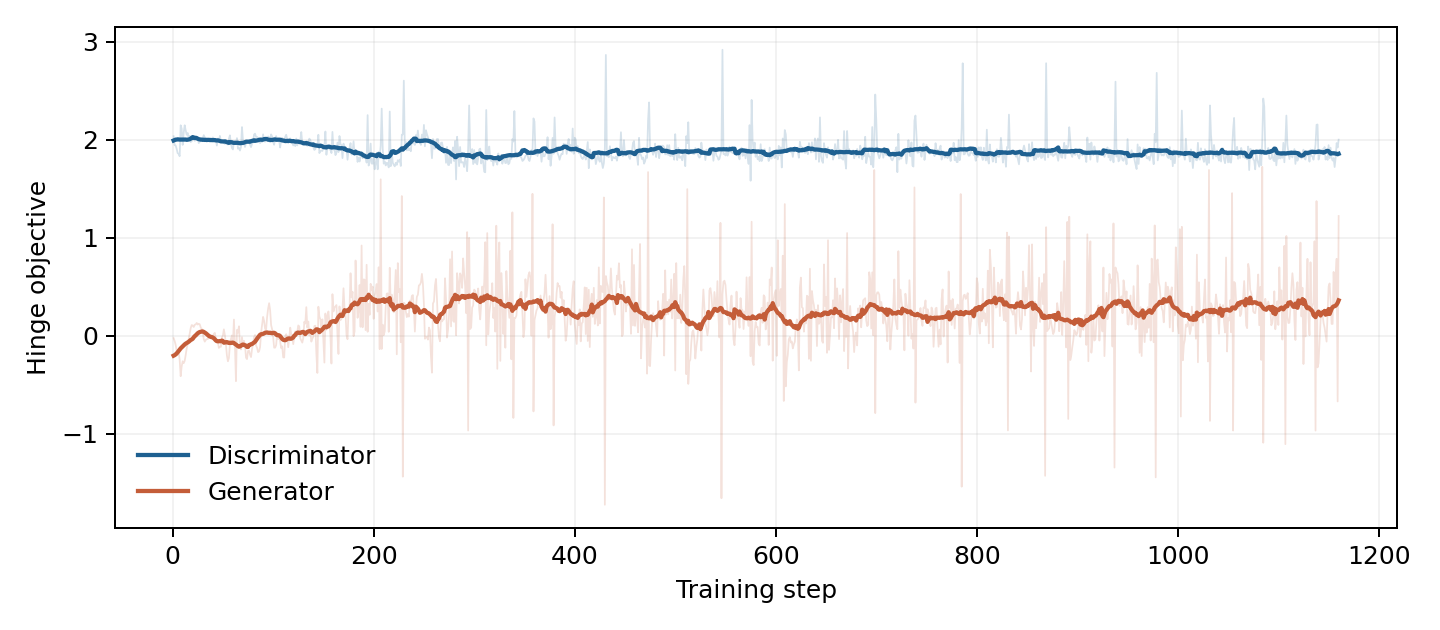

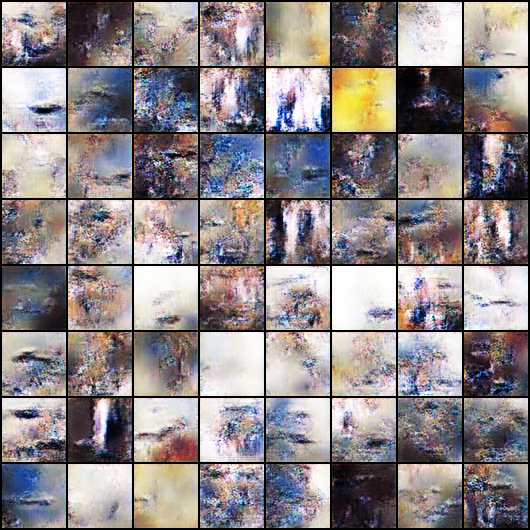

In [14]:
import json
from IPython.display import Image as NotebookImage, display

checkpoint = torch.load(PROJECT / 'run' / 'checkpoint.pt', map_location='cpu', weights_only=False)
(PROJECT / 'model').mkdir(exist_ok=True)
torch.save({'generator': checkpoint['generator'],
            'latent_dim': checkpoint['config']['latent_dim'],
            'width': checkpoint['config']['width'],
            'epoch': checkpoint['epoch']}, PROJECT / 'model' / 'kaggle_generator.pt')
metrics = json.loads((PROJECT / 'run' / 'metrics.json').read_text())
print(json.dumps(metrics, indent=2))
display(NotebookImage(filename=str(PROJECT / 'run' / 'loss_curves.png')))
display(NotebookImage(filename=str(PROJECT / 'run' / 'samples_epoch_40.png')))


### Files to retain

After **Save Version > Save & Run All** completes, download `run/metrics.json`, `run/loss_curves.png`, `run/samples_epoch_40.png`, `run/config.json`, `data/images/kaggle_provenance.json`, and `model/kaggle_generator.pt` from the notebook outputs. The checkpoint in `run/checkpoint.pt` is also available if you need to resume or reproduce sampling.
